# **MobileNetV2- transfer learning - EuroSAT**

Set-up Colab paths

In [1]:
import time, json, hashlib, zipfile
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED, BATCH, IMG_SIZE = 42, 32, (64, 64)       # same as Model B
tf.keras.utils.set_random_seed(SEED)

ROOT       = Path("/content")
DATA_ROOT  = ROOT / "data"
SPLIT_CSV  = DATA_ROOT / "eurosat_split.csv"   # the group's shared split (uploaded below)
ZIP_PATH   = DATA_ROOT / "EuroSAT_RGB.zip"
DATASET_URL = "https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip?download=1"
DATASET_MD5 = "f46e308c4d50d4bf32fedad2d3d62f3b"   # official checksum (same one Model B's notebook uses)

DATA_ROOT.mkdir(exist_ok=True)
(ROOT / "results").mkdir(exist_ok=True); (ROOT / "figures").mkdir(exist_ok=True)
print("TF", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU") or "none")

TF 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# Upload the split CSV
from google.colab import files

if not SPLIT_CSV.exists():
    uploaded = files.upload()                       # choose eurosat_split.csv in the dialog
    name = next(iter(uploaded))
    Path(name).rename(SPLIT_CSV)

split_check = pd.read_csv(SPLIT_CSV, dtype=str)
print(split_check.columns.tolist())                 # expect ['file', 'label', 'split']
print(split_check.groupby("split").size().to_dict())   # expect train 18900 / val 4050 / test 4050

Saving eurosat_split.csv to eurosat_split.csv
['file', 'label', 'split']
{'test': 4050, 'train': 18900, 'val': 4050}


Download and extract EuroSat dataset

In [3]:
def md5_of(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

# Download once (-c resumes if the connection drops)
if not ZIP_PATH.exists():
    !wget -c -q --show-progress -O "{ZIP_PATH}" "{DATASET_URL}"

# Verify the file is complete and uncorrupted
assert md5_of(ZIP_PATH) == DATASET_MD5, "MD5 mismatch: delete the zip and re-run this cell"
print("Checksum OK")

# Extract once
EXTRACT_DIR = DATA_ROOT / "eurosat"
if not EXTRACT_DIR.exists():
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(EXTRACT_DIR)

# Find the folder that directly contains the class folders (robust to the zip's layout)
DATA_DIR = next(p.parent for p in EXTRACT_DIR.rglob("AnnualCrop") if p.is_dir())
print("Images are in:", DATA_DIR)
print(sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir()))

/content/data/EuroS 100%[===================>]  90.27M  7.75MB/s    in 24s     
Checksum OK
Images are in: /content/data/eurosat/EuroSAT_RGB
['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


Load data

In [4]:
df = pd.read_csv(SPLIT_CSV, dtype=str)                       # columns: file, label, split
df["path"] = [str(DATA_DIR / l / f) for l, f in zip(df.label, df.file)]
assert all(Path(p).exists() for p in df.path.head(50)), "Image paths don't match: check DATA_DIR"

CLASS_NAMES = sorted(df.label.unique())
df["y"] = df.label.map({c: i for i, c in enumerate(CLASS_NAMES)})

def load_image(path, label):
    img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    img = tf.ensure_shape(img, IMG_SIZE + (3,))
    return tf.image.convert_image_dtype(img, tf.float32), label   # pixels scaled to [0, 1]

def make_ds(split_name, shuffle):
    d = df[df.split == split_name].sort_values(["label", "file"])
    ds = tf.data.Dataset.from_tensor_slices(
        (d.path.to_numpy(dtype=str), d.y.to_numpy(dtype=np.int32)))
    if shuffle:
        ds = ds.shuffle(len(d), seed=SEED)
    return ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds, val_ds, test_ds = make_ds("train", True), make_ds("val", False), make_ds("test", False)
print(df.groupby("split").size().to_dict())    # expect 18900 / 4050 / 4050

{'test': 4050, 'train': 18900, 'val': 4050}


Build MobileNetV2 with a new 10-class head

In [5]:
import warnings
warnings.filterwarnings("ignore", message=".*input_shape. is undefined.*")   # harmless 224x224-weights notice

def build_mobilenetv2():
    """MobileNetV2 backbone (ImageNet weights) + new 10-class head.
    BatchNorm layers always run in inference mode, so the pretrained statistics are kept."""
    base = tf.keras.applications.MobileNetV2(
        input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")
    base.trainable = False

    inputs = layers.Input(shape=IMG_SIZE + (3,))
    x = layers.Rescaling(2.0, offset=-1.0)(inputs)      # [0,1] -> [-1,1], what MobileNetV2 expects
    x = base(x, training=False)                         # keep BatchNorm in inference mode
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(len(CLASS_NAMES), activation="softmax")(x)   # the new head
    return models.Model(inputs, outputs, name="MobileNetV2"), base

model, base = build_mobilenetv2()
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 2, 2, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

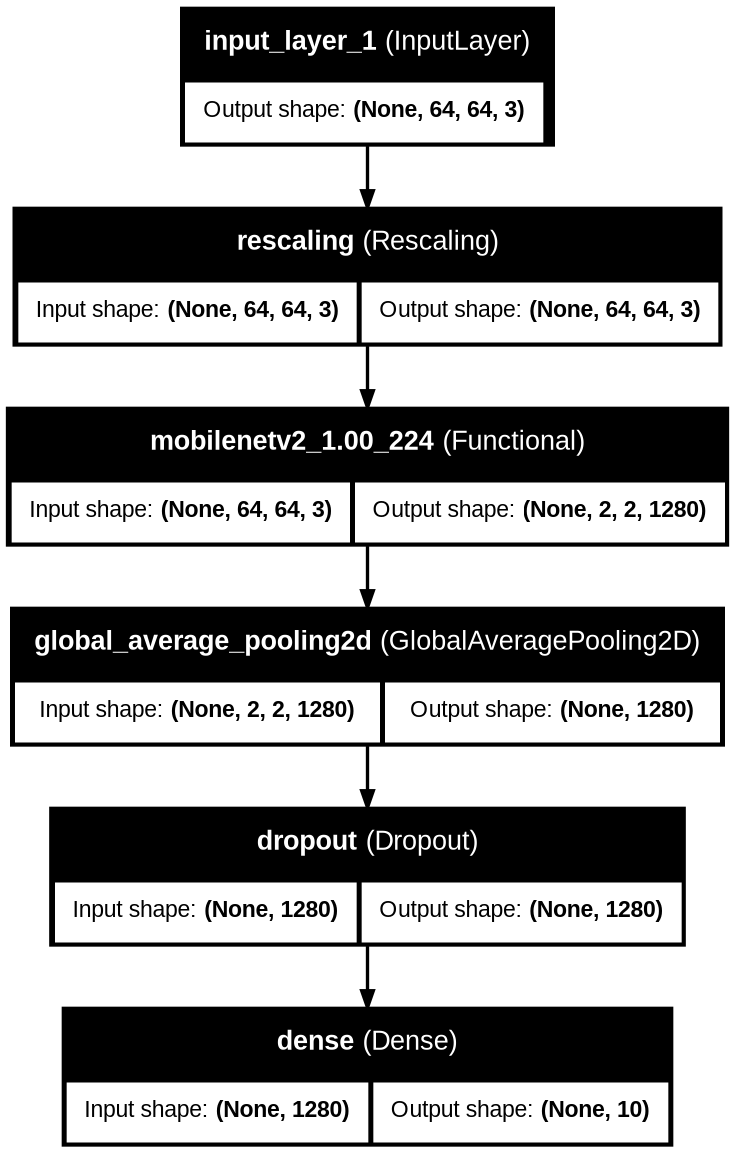

In [6]:
# plot the model architecture
tf.keras.utils.plot_model(model, to_file="figures/mobilenetv2_top.png",
                          show_shapes=True, show_layer_names=True, dpi=120)

## Fine-tuning experiments

Every strategy below trains the **same MobileNetV2 for the same 20 epochs** on the same split, starting from the same initial head (seed 42). Only the *recipe* changes, so differences in the results come from the fine-tuning method.

| Strategy | What it does |
|---|---|
| `feature_extraction` | Backbone frozen for all 20 epochs, only the new head is trained |
| `full_finetune` | All layers trainable from epoch 1 (lr 1e-4) |
| `two_stage` | 5 epochs head only, then 15 epochs all layers (our original recipe) |

The best epoch of each run is chosen by **validation loss**, and the strategies are ranked by **validation accuracy**. The test set is only reported, never used to choose.

In [7]:
from sklearn.metrics import precision_recall_fscore_support

# ---------- settings ----------
try:
    HARDWARE = "Colab " + tf.config.experimental.get_device_details(
        tf.config.list_physical_devices("GPU")[0]).get("device_name", "GPU")
except Exception:
    HARDWARE = "Colab CPU"

LOSS = "sparse_categorical_crossentropy"
EPOCHS_PER_RUN = 20            # same budget for every strategy (matches Model B's 20 epochs)

RESULTS_DIR = Path("results");  FIGS_DIR = Path("figures");  WEIGHTS_DIR = RESULTS_DIR / "weights"
for d in (RESULTS_DIR, FIGS_DIR, WEIGHTS_DIR):
    d.mkdir(exist_ok=True)

# unfreeze: "none" = backbone frozen | "all" = whole backbone trainable
HEAD_THEN_ALL = [dict(epochs=5,  lr=1e-3, unfreeze="none"),
                 dict(epochs=15, lr=1e-4, unfreeze="all")]

STRATEGIES = {
    "feature_extraction": dict(
        desc="Backbone frozen for all epochs; only the new head is trained (Adam 1e-3).",
        stages=[dict(epochs=20, lr=1e-3, unfreeze="none")]),
    "full_finetune": dict(
        desc="All layers trainable from epoch 1, single stage (Adam 1e-4).",
        stages=[dict(epochs=20, lr=1e-4, unfreeze="all")]),
    "two_stage": dict(
        desc="5 epochs head only (1e-3), then 15 epochs all layers (1e-4).",
        stages=HEAD_THEN_ALL),
}
for _name, _cfg in STRATEGIES.items():
    assert sum(s["epochs"] for s in _cfg["stages"]) == EPOCHS_PER_RUN, f"{_name}: stages must add up to {EPOCHS_PER_RUN} epochs"

r4 = lambda v: round(float(v), 4)
print("Hardware:", HARDWARE, "| strategies:", list(STRATEGIES))

Hardware: Colab Tesla T4 | strategies: ['feature_extraction', 'full_finetune', 'two_stage']


In [8]:
class RunTracker(tf.keras.callbacks.Callback):
    """Records the time of every epoch and keeps the best-validation-loss weights across ALL stages of one run."""
    def __init__(self):
        super().__init__()
        self.stage = 1
        self.epoch_times, self.epoch_stage = [], []
        self.best_val_loss, self.best_weights, self.best_epoch = float("inf"), None, 0

    def on_epoch_begin(self, epoch, logs=None):
        self.t0 = time.perf_counter()

    def on_epoch_end(self, epoch, logs=None):
        self.epoch_times.append(time.perf_counter() - self.t0)
        self.epoch_stage.append(self.stage)
        if logs["val_loss"] < self.best_val_loss:
            self.best_val_loss = logs["val_loss"]
            self.best_epoch = len(self.epoch_times)          # counted over the whole run
            self.best_weights = self.model.get_weights()


def set_backbone_trainable(base, unfreeze):
    """unfreeze: "none" (backbone frozen) or "all" (whole backbone trainable)."""
    base.trainable = (unfreeze == "all")


def n_trainable(m):
    return int(sum(np.prod(w.shape) for w in m.trainable_weights))


def count_macs(m):                                   # conv + dense only, BatchNorm excluded (Model B's rule)
    n = 0
    for layer in m.layers:
        if isinstance(layer, tf.keras.Model):
            n += count_macs(layer)
        elif isinstance(layer, layers.DepthwiseConv2D):
            h, w, c = layer.output.shape[1:]
            n += h * w * layer.kernel_size[0] * layer.kernel_size[1] * c
        elif isinstance(layer, layers.Conv2D):
            h, w, c_out = layer.output.shape[1:]
            n += h * w * layer.kernel_size[0] * layer.kernel_size[1] * layer.input.shape[-1] * c_out
        elif isinstance(layer, layers.Dense):
            n += layer.input.shape[-1] * layer.units
    return n


def evaluate_on_test(model):
    test_loss = float(model.evaluate(test_ds, verbose=0)[0])
    y_true = np.concatenate([y.numpy() for _, y in test_ds])          # test_ds is not shuffled
    y_pred = np.argmax(model.predict(test_ds, verbose=0), axis=1)
    p_m, r_m, f_m, _ = precision_recall_fscore_support(y_true, y_pred, average="macro")
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred)
    return dict(
        test_loss=r4(test_loss), test_accuracy=r4((y_true == y_pred).mean()),
        precision_macro=r4(p_m), recall_macro=r4(r_m), f1_macro=r4(f_m),
        per_class={c: {"precision": r4(p[i]), "recall": r4(r[i]), "f1": r4(f[i])}
                   for i, c in enumerate(CLASS_NAMES)},
        confusion_matrix=confusion_matrix(y_true, y_pred).tolist())

In [9]:
def run_strategy(name, cfg):
    """Train one fine-tuning strategy from scratch and return all of its results as a dict."""
    print(f"\n{'=' * 78}\n{name}: {cfg['desc']}\n{'=' * 78}")
    tf.keras.utils.set_random_seed(SEED)                  # identical initial head for every strategy
    model, base = build_mobilenetv2()
    tracker = RunTracker()
    hist = {k: [] for k in ["loss", "val_loss", "accuracy", "val_accuracy"]}
    stages = []

    for i, st in enumerate(cfg["stages"], start=1):
        set_backbone_trainable(base, st["unfreeze"])
        model.compile(tf.keras.optimizers.Adam(st["lr"]), loss=LOSS, metrics=["accuracy"])   # re-compile after changing trainable
        stages.append(dict(stage=i, epochs=st["epochs"], learning_rate=st["lr"],
                           unfrozen=str(st["unfreeze"]), trainable_params=n_trainable(model)))
        print(f"-- stage {i}: {st['epochs']} epochs, lr {st['lr']}, backbone unfrozen: {st['unfreeze']}, "
              f"trainable params: {stages[-1]['trainable_params']:,}")
        tracker.stage = i
        h = model.fit(train_ds, validation_data=val_ds, epochs=st["epochs"], callbacks=[tracker], verbose=2)
        for k in hist:
            hist[k] += h.history[k]

    model.set_weights(tracker.best_weights)               # back to the best-validation epoch
    model.save_weights(WEIGHTS_DIR / f"{name}.weights.h5")

    # timing: skip the first epoch of every stage (graph tracing makes it much slower)
    times, stg = np.array(tracker.epoch_times), np.array(tracker.epoch_stage)
    first = np.r_[True, stg[1:] != stg[:-1]]
    for s in stages:
        m = (stg == s["stage"]) & ~first
        s["time_per_epoch_s"] = round(float(times[m].mean()), 2) if m.any() else None

    be = tracker.best_epoch
    res = dict(
        description=cfg["desc"], hardware=HARDWARE, seed=SEED, batch_size=BATCH,
        stages=stages, epochs=len(hist["loss"]), best_epoch=be,
        train_accuracy=r4(hist["accuracy"][be - 1]),
        val_loss=r4(hist["val_loss"][be - 1]), val_accuracy=r4(hist["val_accuracy"][be - 1]),
        time_per_epoch_s=round(float(times[~first].mean()), 2),
        total_train_time_s=round(float(times.sum()), 1))
    res.update(evaluate_on_test(model))
    res["history"] = {**{k: [r4(v) for v in vals] for k, vals in hist.items()},
                      "epoch_time_s": [round(float(t), 2) for t in times], "stage": [int(s) for s in stg]}
    print(f"=> best epoch {be} | val acc {res['val_accuracy']:.2%} | test acc {res['test_accuracy']:.2%} "
          f"| {res['time_per_epoch_s']} s/epoch")
    return res

In [10]:
# ---------- reporting helpers: ranking, summary table, figures ----------
from matplotlib.ticker import ScalarFormatter

def rank_strategies(strategies):
    """Best first: highest validation accuracy, ties broken by lower validation loss (test set is NOT used)."""
    return sorted(strategies, key=lambda n: (-strategies[n]["val_accuracy"], strategies[n]["val_loss"]))


def summary_table(strategies):
    rows = []
    for rank, n in enumerate(rank_strategies(strategies), start=1):
        r = strategies[n]
        rows.append({
            "rank": rank, "strategy": n,
            "trainable params": f"{max(s['trainable_params'] for s in r['stages']):,}",
            "best epoch": r["best_epoch"],
            "val loss": f"{r['val_loss']:.4f}", "val acc %": f"{r['val_accuracy'] * 100:.2f}",
            "test acc %": f"{r['test_accuracy'] * 100:.2f}", "macro F1": f"{r['f1_macro']:.4f}",
            "s/epoch": f"{r['time_per_epoch_s']:.1f}", "train min": f"{r['total_train_time_s'] / 60:.1f}"})
    return pd.DataFrame(rows)


def plot_comparison(strategies, path):
    order = rank_strategies(strategies)
    color = {n: plt.cm.tab10(i % 10) for i, n in enumerate(strategies)}
    fig, ax = plt.subplots(2, 2, figsize=(14, 9.5))

    # (a, b) validation curves; star = selected epoch, dotted line = where the next stage starts
    for n in order:
        r = strategies[n]; h = r["history"]; be = r["best_epoch"]
        x = np.arange(1, len(h["val_loss"]) + 1)
        for a, key, scale in ((ax[0, 0], "val_loss", 1), (ax[0, 1], "val_accuracy", 100)):
            y = np.array(h[key]) * scale
            a.plot(x, y, color=color[n], lw=1.8, label=n)
            a.scatter([be], [y[be - 1]], color=color[n], marker="*", s=150, edgecolor="black", zorder=5)
            done = 0
            for st in r["stages"][:-1]:
                done += st["epochs"]
                a.axvline(done + 0.5, color=color[n], ls=":", alpha=0.5)
    ax[0, 0].set(title="Validation loss (star = selected epoch)", xlabel="Epoch", ylabel="Validation loss (log scale)")
    ax[0, 0].set_yscale("log")
    for fmt in (ax[0, 0].yaxis.set_major_formatter, ax[0, 0].yaxis.set_minor_formatter):
        fmt(ScalarFormatter())                            # plain numbers on the log axis
    ax[0, 0].tick_params(axis="y", which="minor", labelsize=7)
    ax[0, 1].set(title="Validation accuracy", xlabel="Epoch", ylabel="Accuracy (%)")
    ax[0, 1].set_ylim(60, 100)
    for a in ax[0]:
        a.grid(alpha=0.3)
    ax[0, 0].legend(fontsize=8)

    # (c) accuracy of the selected model: validation vs test
    xs = np.arange(len(order)); w = 0.38
    val = [strategies[n]["val_accuracy"] * 100 for n in order]
    test = [strategies[n]["test_accuracy"] * 100 for n in order]
    b1 = ax[1, 0].bar(xs - w / 2, val, w, label="Validation", color="#9ecae1")
    b2 = ax[1, 0].bar(xs + w / 2, test, w, label="Test", color="#3182bd")
    for bars in (b1, b2):
        for b in bars:
            ax[1, 0].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.1, f"{b.get_height():.1f}",
                          ha="center", va="bottom", fontsize=8)
    ax[1, 0].set_xticks(xs, order, rotation=20, ha="right")
    ax[1, 0].set_ylim(min(val + test) - 3, 100.5)
    ax[1, 0].set(title="Accuracy of the selected epoch (ranked by validation)", ylabel="Accuracy (%)")
    ax[1, 0].legend(); ax[1, 0].grid(axis="y", alpha=0.3)

    # (d) cost vs benefit
    tmax = max(max(s["trainable_params"] for s in strategies[n]["stages"]) for n in order)
    for n in order:
        r = strategies[n]
        tp = max(s["trainable_params"] for s in r["stages"])
        px, py = r["total_train_time_s"] / 60, r["test_accuracy"] * 100
        ax[1, 1].scatter(px, py, s=60 + 340 * tp / tmax, color=color[n], edgecolor="black", alpha=0.85)
        ax[1, 1].annotate(n, (px, py), textcoords="offset points", xytext=(7, 7), fontsize=8)
    ax[1, 1].set(title="Test accuracy vs training time (bubble size = trainable parameters)",
                 xlabel="Total training time (minutes)", ylabel="Test accuracy (%)")
    ax[1, 1].grid(alpha=0.3)
    ax[1, 1].margins(x=0.15, y=0.15)

    fig.suptitle("MobileNetV2 fine-tuning strategies on EuroSAT (same split, same 20-epoch budget)", fontsize=13)
    plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()


def plot_per_class_f1(strategies, class_names, path):
    order = rank_strategies(strategies)
    M = np.array([[strategies[n]["per_class"][c]["f1"] for c in class_names] for n in order])
    lo = max(0.0, float(M.min()) - 0.05)
    fig, ax = plt.subplots(figsize=(1.0 * len(class_names) + 3, 0.65 * len(order) + 2.2))
    im = ax.imshow(M, cmap="Blues", vmin=lo, vmax=1.0, aspect="auto")
    ax.set_xticks(range(len(class_names)), class_names, rotation=40, ha="right")
    ax.set_yticks(range(len(order)), order)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if M[i, j] > (lo + 1) / 2 else "black")
    ax.set_title("Per-class F1 on the test set (rows ranked by validation accuracy)")
    fig.colorbar(im, ax=ax, fraction=0.03)
    plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()


def plot_confusion(result, class_names, title, path):
    fig, ax = plt.subplots(figsize=(10, 8))
    ConfusionMatrixDisplay(np.array(result["confusion_matrix"]), display_labels=class_names).plot(
        ax=ax, cmap="Blues", xticks_rotation=90, values_format="d", colorbar=False)
    ax.set_title(f"{title} (test accuracy {result['test_accuracy']:.2%})")
    plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()

### Run the strategies

Each run takes a few minutes on a GPU. Results are written to `results/finetuning_results.json` after every strategy, so a disconnect does not lose finished runs (re-running this cell skips them).

In [11]:
RESULTS_JSON = RESULTS_DIR / "finetuning_results.json"
all_results = json.load(open(RESULTS_JSON)) if RESULTS_JSON.exists() else {"strategies": {}}

RUN_ONLY  = None      # e.g. ["two_stage", "full_finetune"] to run a subset
SKIP_DONE = True      # skip strategies that are already in finetuning_results.json


def save_results():
    strat = all_results["strategies"]
    common = all_results.setdefault("common", {})
    if "total_params" not in common:                      # same architecture for every strategy
        m, _ = build_mobilenetv2()
        common.update(total_params=int(m.count_params()), macs=int(count_macs(m)))
    all_results["meta"] = dict(
        model="MobileNetV2 (ImageNet weights, new 10-class head)", dataset="EuroSAT RGB, shared split file",
        image_size=list(IMG_SIZE), batch_size=BATCH, seed=SEED, epochs_per_run=EPOCHS_PER_RUN,
        optimizer="Adam", loss=LOSS, hardware=HARDWARE, tensorflow=tf.__version__,
        split_sizes={k: int(v) for k, v in df.groupby("split").size().items()},
        class_names=list(CLASS_NAMES),
        selection="best epoch per run by validation loss; strategies ranked by validation accuracy (ties: validation loss)")
    all_results["ranking_by_validation"] = rank_strategies(strat) if strat else []
    all_results["best_by_validation"] = all_results["ranking_by_validation"][0] if strat else None
    with open(RESULTS_JSON, "w") as f:
        json.dump(all_results, f, indent=2)


for name, cfg in STRATEGIES.items():
    if RUN_ONLY and name not in RUN_ONLY:
        continue
    if SKIP_DONE and name in all_results["strategies"]:
        print(f"Skipping {name} (already in {RESULTS_JSON.name})")
        continue
    all_results["strategies"][name] = run_strategy(name, cfg)
    save_results()

print("\nSaved:", RESULTS_JSON)


feature_extraction: Backbone frozen for all epochs; only the new head is trained (Adam 1e-3).
-- stage 1: 20 epochs, lr 0.001, backbone unfrozen: none, trainable params: 12,810
Epoch 1/20
591/591 - 32s - 54ms/step - accuracy: 0.7677 - loss: 0.7180 - val_accuracy: 0.8449 - val_loss: 0.4724
Epoch 2/20
591/591 - 6s - 10ms/step - accuracy: 0.8579 - loss: 0.4380 - val_accuracy: 0.8583 - val_loss: 0.4160
Epoch 3/20
591/591 - 6s - 11ms/step - accuracy: 0.8743 - loss: 0.3844 - val_accuracy: 0.8642 - val_loss: 0.4071
Epoch 4/20
591/591 - 10s - 17ms/step - accuracy: 0.8830 - loss: 0.3532 - val_accuracy: 0.8627 - val_loss: 0.4167
Epoch 5/20
591/591 - 10s - 17ms/step - accuracy: 0.8882 - loss: 0.3361 - val_accuracy: 0.8635 - val_loss: 0.4144
Epoch 6/20
591/591 - 10s - 18ms/step - accuracy: 0.8912 - loss: 0.3204 - val_accuracy: 0.8694 - val_loss: 0.4172
Epoch 7/20
591/591 - 6s - 10ms/step - accuracy: 0.8950 - loss: 0.3119 - val_accuracy: 0.8686 - val_loss: 0.4201
Epoch 8/20
591/591 - 10s - 17ms/st

### Compare the strategies

 rank           strategy trainable params  best epoch val loss val acc % test acc % macro F1 s/epoch train min
    1      full_finetune        2,236,682          20   0.1460     96.12      96.47   0.9641    12.4       5.6
    2          two_stage        2,236,682          13   0.1700     95.83      96.47   0.9630    11.0       4.9
    3 feature_extraction           12,810           3   0.4071     86.42      87.21   0.8678     7.8       3.0


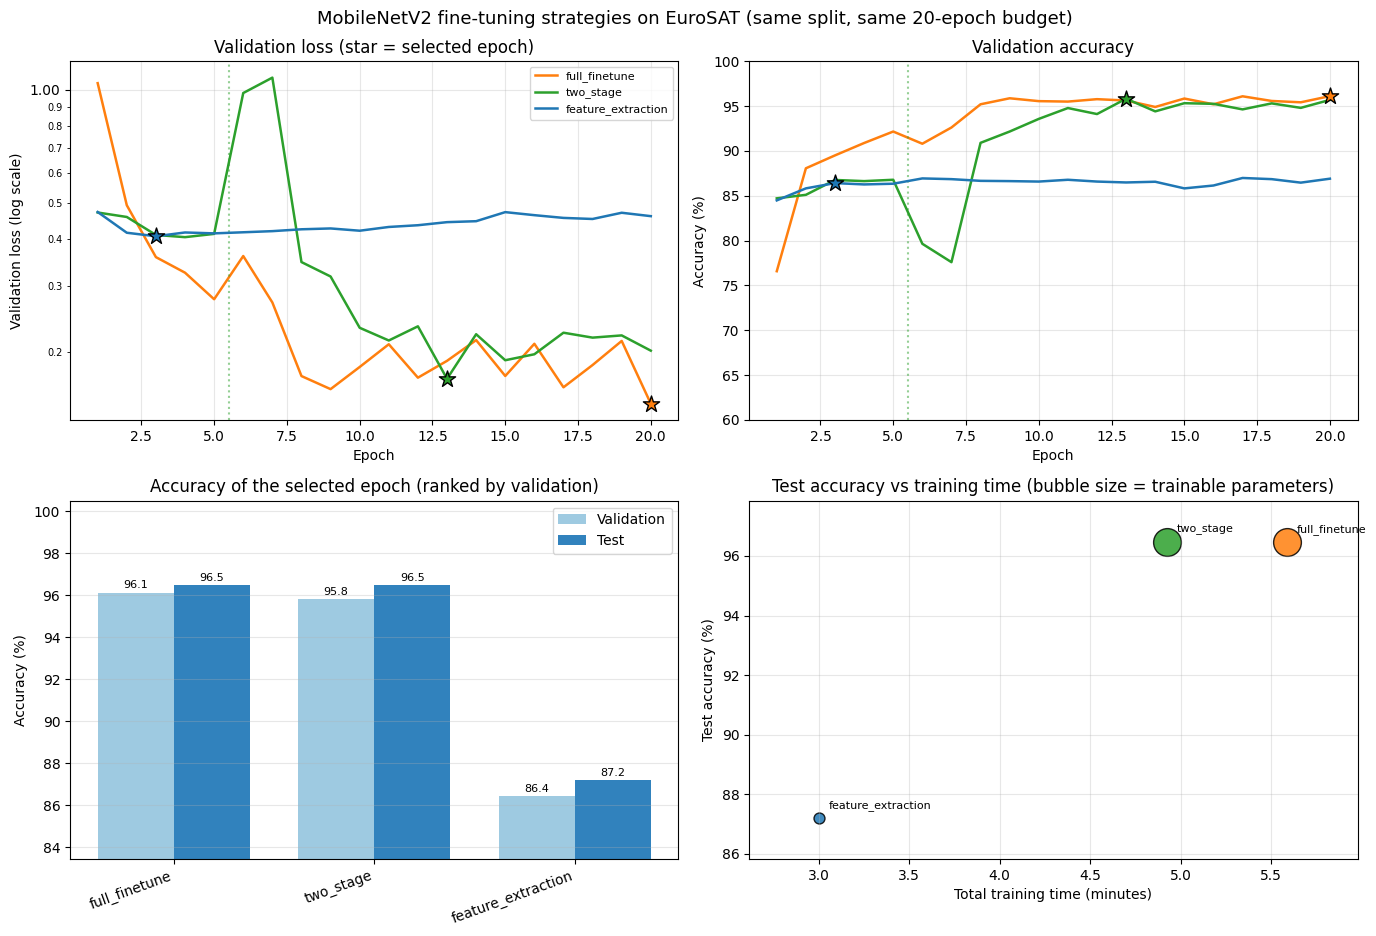

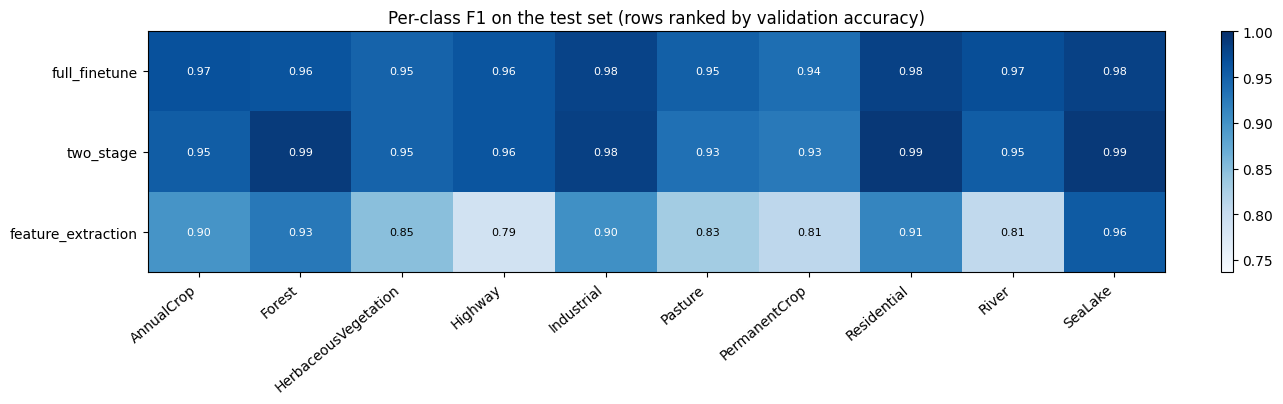

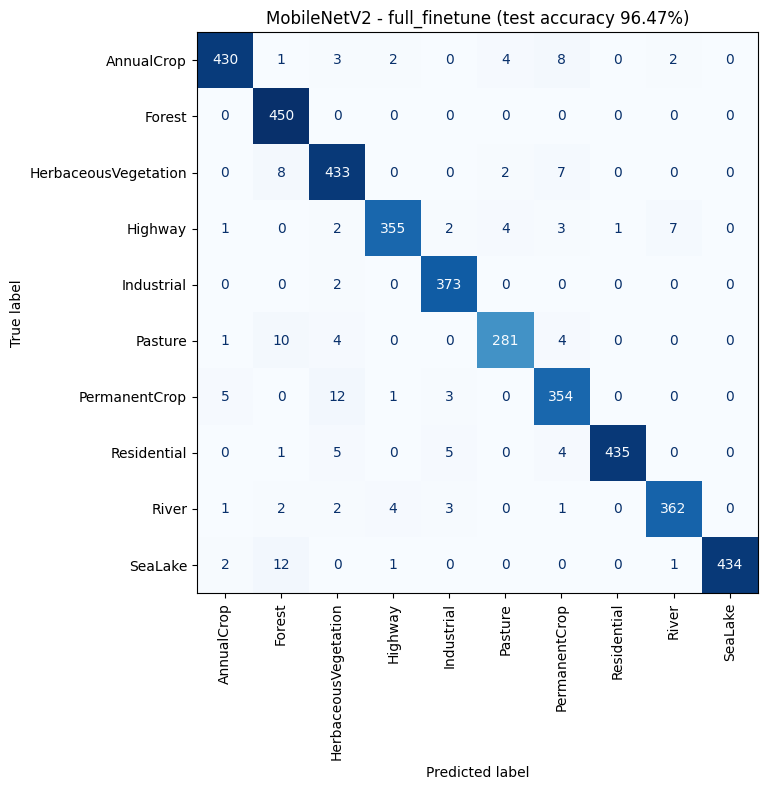


Best strategy by validation accuracy: full_finetune


In [12]:
strategies = all_results["strategies"]
print(summary_table(strategies).to_string(index=False))

plot_comparison(strategies, FIGS_DIR / "finetune_comparison.png")
plot_per_class_f1(strategies, CLASS_NAMES, FIGS_DIR / "finetune_per_class_f1.png")

best = all_results["best_by_validation"]
plot_confusion(strategies[best], CLASS_NAMES, f"MobileNetV2 - {best}", FIGS_DIR / "finetune_best_confusion.png")
print(f"\nBest strategy by validation accuracy: {best}")

### Export the best strategy

Writes `results/mobilenetv2.keras` (uncompiled, for the size measurement) and `results/mobilenetv2.json` in the same format as the Model A file, so the group comparison table works unchanged.

In [13]:
best = all_results["best_by_validation"]
r = all_results["strategies"][best]

# rebuild the best model and reload its saved best-epoch weights
final, final_base = build_mobilenetv2()
final_base.trainable = True                              # count what was actually trained
final.load_weights(WEIGHTS_DIR / f"{best}.weights.h5")

final.compile(loss=LOSS, metrics=["accuracy"])           # sanity check: reload reproduces the saved test accuracy
print(f"Reloaded test accuracy {final.evaluate(test_ds, verbose=0)[1]:.4f} (saved: {r['test_accuracy']:.4f})")

model_path = RESULTS_DIR / "mobilenetv2.keras"
final.save(model_path)
size_kb = model_path.stat().st_size / 1024               # KiB, 1024-based like Model A
all_results["common"].update(size_kb=round(size_kb, 1), size_mb=round(size_kb / 1024, 3))
save_results()

common = all_results["common"]
model_a_format = {
    "model": "MobileNetV2",
    "trainable_params": max(s["trainable_params"] for s in r["stages"]),
    "total_params": common["total_params"],
    "macs": common["macs"],
    "size_kb": common["size_kb"],
    "size_mb": common["size_mb"],
    "epochs": r["epochs"],
    "time_per_epoch_s": r["time_per_epoch_s"],
    "device": r["hardware"],
    "batch_size": r["batch_size"],
    "optimizer": "Adam",
    "learning_rate": r["stages"][-1]["learning_rate"],
    "test_accuracy": r["test_accuracy"],
    "precision_macro": r["precision_macro"],
    "recall_macro": r["recall_macro"],
    "f1_macro": r["f1_macro"],
    "per_class": r["per_class"],
    "class_names": list(CLASS_NAMES),
    "confusion_matrix": r["confusion_matrix"],
    "history": {k: r["history"][k] for k in ["loss", "val_loss", "accuracy", "val_accuracy"]},
    "best_epoch": r["best_epoch"],
    "fine_tuning_strategy": best,
}
with open(RESULTS_DIR / "mobilenetv2.json", "w") as f:
    json.dump(model_a_format, f, indent=2)

print(f"Best strategy: {best} | params {common['total_params']:,} | {common['size_kb']:.1f} KiB | "
      f"{common['macs']:,} MACs | test acc {r['test_accuracy']:.2%}")

Reloaded test accuracy 0.9647 (saved: 0.9647)
Best strategy: full_finetune | params 2,270,794 | 9446.0 KiB | 24,461,312 MACs | test acc 96.47%
